<a href="https://colab.research.google.com/github/nisabulut/digital-image-processing/blob/main/4_8_goruntu_isleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [20]:
%%writefile canny_sifirdan.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <cmath>
#include <vector>

using namespace cv;
using namespace std;

// 1. ALT FONKSİYON: Gürültü Bastırma (5x5 Gauss Filtresi)
Mat applyGaussian5x5(const Mat& src) {
    Mat dst = Mat::zeros(src.size(), CV_32F);
    float kernel[5][5] = {
        {2/159.0f, 4/159.0f,  5/159.0f,  4/159.0f, 2/159.0f},
        {4/159.0f, 9/159.0f,  12/159.0f, 9/159.0f, 4/159.0f},
        {5/159.0f, 12/159.0f, 15/159.0f, 12/159.0f, 5/159.0f},
        {4/159.0f, 9/159.0f,  12/159.0f, 9/159.0f, 4/159.0f},
        {2/159.0f, 4/159.0f,  5/159.0f,  4/159.0f, 2/159.0f}
    };
    for (int r = 2; r < src.rows - 2; ++r) {
        for (int c = 2; c < src.cols - 2; ++c) {
            float sum = 0.0f;
            for (int kr = -2; kr <= 2; ++kr) {
                for (int kc = -2; kc <= 2; ++kc) {
                    sum += src.at<uchar>(r + kr, c + kc) * kernel[kr + 2][kc + 2];
                }
            }
            dst.at<float>(r, c) = sum;
        }
    }
    return dst;
}

// 2. ALT FONKSİYON: Sobel Filtresi ile Gradyan (Büyüklük ve Yön) Hesaplama
void calculateGradientsSobel(const Mat& src, Mat& magnitude, Mat& angle) {
    magnitude = Mat::zeros(src.size(), CV_32F);
    angle = Mat::zeros(src.size(), CV_32F);
    int Gx[3][3] = {{-1, 0, 1}, {-2, 0, 2}, {-1, 0, 1}};
    int Gy[3][3] = {{-1, -2, -1}, {0, 0, 0}, {1, 2, 1}};

    for (int r = 1; r < src.rows - 1; ++r) {
        for (int c = 1; c < src.cols - 1; ++c) {
            float sumX = 0.0f, sumY = 0.0f;
            for (int kr = -1; kr <= 1; ++kr) {
                for (int kc = -1; kc <= 1; ++kc) {
                    float val = src.at<float>(r + kr, c + kc);
                    sumX += val * Gx[kr + 1][kc + 1];
                    sumY += val * Gy[kr + 1][kc + 1];
                }
            }
            magnitude.at<float>(r, c) = sqrt((sumX * sumX) + (sumY * sumY));
            float theta = atan2(sumY, sumX) * (180.0f / CV_PI);
            if (theta < 0) theta += 180.0f;
            angle.at<float>(r, c) = theta;
        }
    }
}

// 3. ALT FONKSİYON: Non-Maximum Suppression (Kenar İnceltme)
Mat nonMaximumSuppression(const Mat& magnitude, const Mat& angle) {
    Mat nms = Mat::zeros(magnitude.size(), CV_32F);
    for (int r = 1; r < magnitude.rows - 1; ++r) {
        for (int c = 1; c < magnitude.cols - 1; ++c) {
            float q = 255.0f, r_val = 255.0f;
            float theta = angle.at<float>(r, c);

            if ((theta >= 0 && theta < 22.5) || (theta >= 157.5 && theta <= 180)) {
                q = magnitude.at<float>(r, c + 1); r_val = magnitude.at<float>(r, c - 1);
            } else if (theta >= 22.5 && theta < 67.5) {
                q = magnitude.at<float>(r + 1, c - 1); r_val = magnitude.at<float>(r - 1, c + 1);
            } else if (theta >= 67.5 && theta < 112.5) {
                q = magnitude.at<float>(r + 1, c); r_val = magnitude.at<float>(r - 1, c);
            } else if (theta >= 112.5 && theta < 157.5) {
                q = magnitude.at<float>(r - 1, c - 1); r_val = magnitude.at<float>(r + 1, c + 1);
            }

            if (magnitude.at<float>(r, c) >= q && magnitude.at<float>(r, c) >= r_val) {
                nms.at<float>(r, c) = magnitude.at<float>(r, c);
            } else {
                nms.at<float>(r, c) = 0.0f;
            }
        }
    }
    return nms;
}

// 4. ALT FONKSİYON: Hysteresis Thresholding (Çift Eşikleme)
Mat hysteresisThresholding(const Mat& nms, float lowThresh, float highThresh) {
    Mat result = Mat::zeros(nms.size(), CV_8UC1);
    uchar WEAK = 75, STRONG = 255;

    for (int r = 0; r < nms.rows; ++r) {
        for (int c = 0; c < nms.cols; ++c) {
            float val = nms.at<float>(r, c);
            if (val >= highThresh) result.at<uchar>(r, c) = STRONG;
            else if (val >= lowThresh && val < highThresh) result.at<uchar>(r, c) = WEAK;
        }
    }

    for (int r = 1; r < result.rows - 1; ++r) {
        for (int c = 1; c < result.cols - 1; ++c) {
            if (result.at<uchar>(r, c) == WEAK) {
                if (result.at<uchar>(r-1, c-1) == STRONG || result.at<uchar>(r-1, c) == STRONG || result.at<uchar>(r-1, c+1) == STRONG ||
                    result.at<uchar>(r, c-1) == STRONG || result.at<uchar>(r, c+1) == STRONG ||
                    result.at<uchar>(r+1, c-1) == STRONG || result.at<uchar>(r+1, c) == STRONG || result.at<uchar>(r+1, c+1) == STRONG) {
                    result.at<uchar>(r, c) = STRONG;
                } else {
                    result.at<uchar>(r, c) = 0;
                }
            }
        }
    }

    for (int r = 0; r < result.rows; ++r) {
        for (int c = 0; c < result.cols; ++c) {
            if (result.at<uchar>(r, c) == WEAK) result.at<uchar>(r, c) = 0;
        }
    }
    return result;
}

int main(int argc, char** argv) {
    if (argc != 2) return -1;
    Mat img = imread(argv[1], IMREAD_GRAYSCALE);
    if (img.empty()) return -1;

    Mat blurred = applyGaussian5x5(img);

    Mat magnitude, angle;
    calculateGradientsSobel(blurred, magnitude, angle);

    Mat nms = nonMaximumSuppression(magnitude, angle);

    Mat final_edges = hysteresisThresholding(nms, 30.0f, 90.0f);

    imwrite("orijinal_resim.jpg", img);
    imwrite("canny_sifirdan_sonuc.jpg", final_edges);

    return 0;
}

Overwriting canny_sifirdan.cpp


In [21]:
!apt-get install libopencv-dev -y > /dev/null 2>&1
!g++ canny_sifirdan.cpp -o canny_sifirdan `pkg-config --cflags --libs opencv4`
!./canny_sifirdan "duvar.jpg"

--- Orijinal Görüntü ---


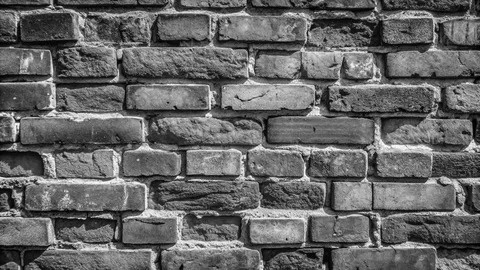


--- Sıfırdan Kodlanan Canny Kenar Tespiti ---


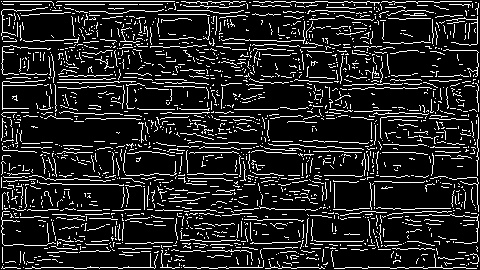

In [22]:
from IPython.display import Image, display

print("--- Orijinal Görüntü ---")
display(Image('orijinal_resim.jpg'))

print("\n--- Sıfırdan Kodlanan Canny Kenar Tespiti ---")
display(Image('canny_sifirdan_sonuc.jpg'))